In [178]:
#Import Libraries
import pandas as pd
import numpy as np
import re

In [179]:
#Load Dataset
df = pd.read_csv(r"S:\Internshala\Projects data sets\morgan_stanely.csv")

In [180]:
#Check the data first rows and columns.
df.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,78,CUST1223,ACC33287,Credit,Withdrawal,Savings Account,Firm E,South,Manager 4,06-01-2023,"81,300.43","40,843.56",0.33,484,13
1,21,CUST8266,ACC58667,Savings,Withdrawal,Credit Card,Firm A,South,Manager 2,17-02-2023,"9,269.64","61,183.04",0.09,836,18
2,176,CUST9420,ACC99117,Credit,Transfer,Home Loan,Firm A,East,Manager 1,13-09-2023,"28,138.55","85,460.13",0.34,451,25
3,167,CUST5253,ACC10117,Loan,Payment,Mutual Fund,Firm D,Central,Manager 1,28-05-2024,"83,943.56","100,525.36",0.61,487,13
4,46,CUST1223,ACC74631,Savings,Deposit,Credit Card,Firm A,East,Manager 4,12-05-2023,"77,104.46","57,425.70",1.04,393,10


In [181]:
# checking the columns,count and datatype
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      800 non-null    int64  
 1   CustomerID         800 non-null    str    
 2   AccountID          800 non-null    str    
 3   AccountType        800 non-null    str    
 4   TransactionType    800 non-null    str    
 5   Product            800 non-null    str    
 6   Firm               800 non-null    str    
 7   Region             800 non-null    str    
 8   Manager            800 non-null    str    
 9   TransactionDate    800 non-null    str    
 10  TransactionAmount  800 non-null    float64
 11  AccountBalance     800 non-null    float64
 12  RiskScore          800 non-null    float64
 13  CreditRating       800 non-null    int64  
 14  TenureMonths       800 non-null    int64  
dtypes: float64(3), int64(3), str(9)
memory usage: 150.0 KB


In [182]:
# checking count,mean,std,min,etc....
df.describe()

,TransactionID,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
count,800.00,800.00,800.00,800.00,800.00,800.00
mean,99.79,"55,194.89","72,764.36",0.47,568.53,119.87
std,57.46,"28,940.34","35,623.57",0.24,155.62,67.36
min,1.00,"-36,173.70","-62,548.72",-0.30,306.00,6.00
25%,50.00,"34,842.16","48,684.20",0.31,437.00,63.00
50%,99.50,"53,768.49","72,908.05",0.49,565.00,118.00
75%,150.00,"74,729.55","95,574.57",0.63,699.50,178.00
max,199.00,"154,662.05","180,539.29",1.25,848.00,238.00


In [183]:
# Task 1 Data Cleaning and Formatting

In [184]:
# Remove/treat any special characters or non-numeric entries from financial fields.

In [185]:
#We need to remove unwanted spaces except digits and decimal points.
financial_cols = ["TransactionAmount", "AccountBalance", "RiskScore", "CreditRating", "TenureMonths"]

for col in financial_cols:
    df[col] = df[col].astype(str)

    for i in range(len(df)):
        df.at[i, col] = re.sub(r'[^0-9.]', '', df.at[i, col])

    df[col] = pd.to_numeric(df[col], errors='coerce')

In [186]:
# Convert currency amounts into numerical format.

In [187]:
#Check the data types
print(df["TransactionAmount"].dtype)
print(df["AccountBalance"].dtype)

float64
float64


In [188]:
#Display sample values
df["TransactionAmount"].head(5)

0   81,300.43
1    9,269.64
2   28,138.55
3   83,943.56
4   77,104.46
Name: TransactionAmount, dtype: float64

In [189]:
#Check for missing values
df.isnull().sum()

TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64

In [190]:
# Validate and Format Date Columns

In [191]:
# Validate the date column
# Your dates are in DD-MM-YYYY format, so use:
df["TransactionDate"] = pd.to_datetime(
    df["TransactionDate"],
    format="%d-%m-%Y"
)

In [192]:
#Check if any invalid dates exist
print(df["TransactionDate"].isnull().sum())

0


In [193]:
#Format the dates
df["TransactionDate"] = df["TransactionDate"].dt.strftime("%Y-%m-%d")

In [194]:
#Verify the result
df["TransactionDate"].head()

0    2023-01-06
1    2023-02-17
2    2023-09-13
3    2024-05-28
4    2023-05-12
Name: TransactionDate, dtype: str

In [195]:
# Ensure account types and transaction categories are standardized.

In [196]:
print("Unique Account Types:")
print(df["AccountType"].unique())

print("\nUnique Transaction Types:")
print(df["TransactionType"].unique())

Unique Account Types:
<ArrowStringArray>
['Credit', 'Savings', 'Loan', 'Current']
Length: 4, dtype: str

Unique Transaction Types:
<ArrowStringArray>
['Withdrawal', 'Transfer', 'Payment', 'Deposit']
Length: 4, dtype: str


In [197]:
#Save the cleaned dataset
df.to_csv("cleaned_morgan_stanley.csv", index=False)

In [198]:
# Task 2: Descriptive Transactional Analysis

In [199]:
# Calculate monthly and yearly summaries of total credits, debits, and net transaction volume

In [200]:
#If TransactionDate was saved as text, convert it back to datetime:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

In [201]:
#checking the data saved or not
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   TransactionID      800 non-null    int64         
 1   CustomerID         800 non-null    str           
 2   AccountID          800 non-null    str           
 3   AccountType        800 non-null    str           
 4   TransactionType    800 non-null    str           
 5   Product            800 non-null    str           
 6   Firm               800 non-null    str           
 7   Region             800 non-null    str           
 8   Manager            800 non-null    str           
 9   TransactionDate    800 non-null    datetime64[us]
 10  TransactionAmount  800 non-null    float64       
 11  AccountBalance     800 non-null    float64       
 12  RiskScore          800 non-null    float64       
 13  CreditRating       800 non-null    int64         
 14  TenureMonths       80

In [202]:
#Create Year and Month columns
df["Year"] = df["TransactionDate"].dt.year
df["Month"] = df["TransactionDate"].dt.month_name()

In [203]:
#Deposit = Credit,Withdrawal = Debit,Payment = Debit
credit = df[df["TransactionType"] == "Deposit"]

debit = df[df["TransactionType"].isin(["Withdrawal", "Payment"])]

In [204]:
pd.set_option("display.float_format", "{:,.2f}".format)

In [205]:
#Monthly Credit
monthly_credit = credit.groupby(["Year", "Month"])["TransactionAmount"].sum()

print(monthly_credit)

Year  Month    
2023  April       652,566.55
      August      473,701.36
      December    540,703.00
      February    790,625.00
      January     739,627.61
      July        776,072.73
      June        537,122.48
      March       428,688.20
      May         467,715.55
      November    529,279.88
      October     954,771.22
      September   863,982.07
2024  April       547,272.22
      February    464,351.73
      January     582,366.95
      June        204,079.15
      March       713,940.90
      May         737,567.66
Name: TransactionAmount, dtype: float64


In [206]:
#Monthly Debit
monthly_debit = debit.groupby(["Year", "Month"])["TransactionAmount"].sum()

print(monthly_debit)

Year  Month    
2023  April       1,735,600.31
      August        973,109.80
      December    1,119,605.15
      February    1,151,100.22
      January     1,268,114.78
      July          966,493.72
      June          635,682.85
      March       1,181,508.20
      May         1,750,275.02
      November    2,012,480.02
      October     1,714,706.35
      September   1,286,274.37
2024  April       1,004,444.88
      February    1,307,505.02
      January       874,822.06
      June        1,486,942.97
      March       1,045,983.99
      May           945,287.44
Name: TransactionAmount, dtype: float64


In [207]:
#Net Transaction Volume
#Net = Credit − Debit
monthly_summary = pd.DataFrame()

monthly_summary["Credit"] = monthly_credit

monthly_summary["Debit"] = monthly_debit

monthly_summary = monthly_summary.fillna(0)

monthly_summary["Net"] = (
    monthly_summary["Credit"]
    - monthly_summary["Debit"]
)

print(monthly_summary)

                   Credit        Debit           Net
Year Month                                          
2023 April     652,566.55 1,735,600.31 -1,083,033.76
     August    473,701.36   973,109.80   -499,408.44
     December  540,703.00 1,119,605.15   -578,902.15
     February  790,625.00 1,151,100.22   -360,475.23
     January   739,627.61 1,268,114.78   -528,487.17
     July      776,072.73   966,493.72   -190,420.99
     June      537,122.48   635,682.85    -98,560.38
     March     428,688.20 1,181,508.20   -752,820.00
     May       467,715.55 1,750,275.02 -1,282,559.48
     November  529,279.88 2,012,480.02 -1,483,200.14
     October   954,771.22 1,714,706.35   -759,935.13
     September 863,982.07 1,286,274.37   -422,292.30
2024 April     547,272.22 1,004,444.88   -457,172.66
     February  464,351.73 1,307,505.02   -843,153.29
     January   582,366.95   874,822.06   -292,455.11
     June      204,079.15 1,486,942.97 -1,282,863.82
     March     713,940.90 1,045,983.99   -332,

In [208]:
# Plot trends in total credits vs. debits over time.

In [209]:
monthly_summary = monthly_summary.reset_index()

In [210]:
#Create a proper date column for plotting
monthly_summary["Date"] = pd.to_datetime(
    monthly_summary["Month"] + " " + monthly_summary["Year"].astype(str),
    format="%B %Y"
)

In [211]:
#Sort the data:
monthly_summary = monthly_summary.sort_values("Date")

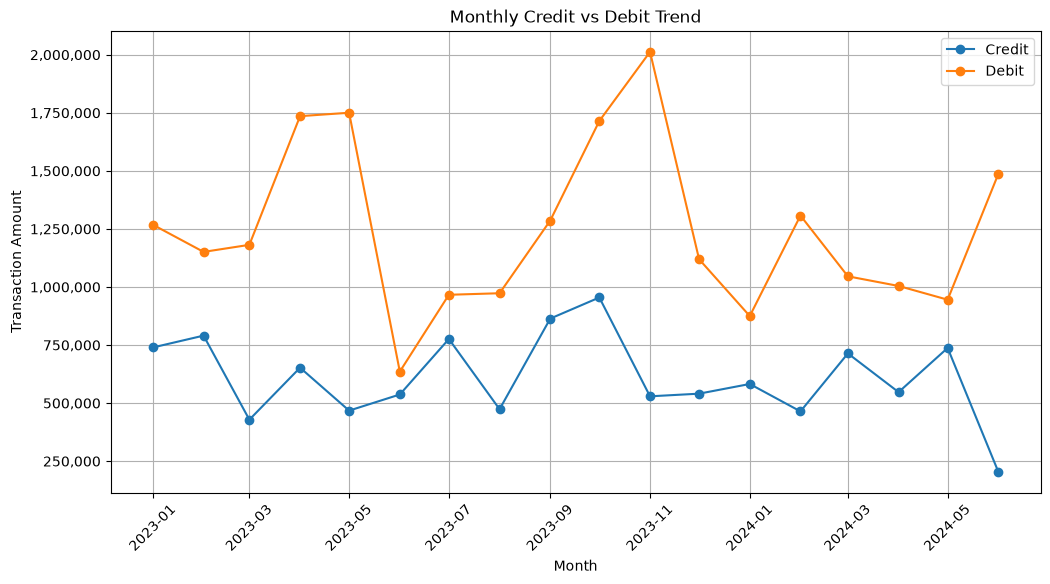

In [212]:
#Plot Credit vs Debit
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


plt.figure(figsize=(12,6))

plt.plot(monthly_summary["Date"],
         monthly_summary["Credit"],
         marker="o",
         label="Credit")

plt.plot(monthly_summary["Date"],
         monthly_summary["Debit"],
         marker="o",
         label="Debit")

plt.title("Monthly Credit vs Debit Trend")
plt.xlabel("Month")
plt.ylabel("Transaction Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.show()

In [213]:
#  Identify top and bottom performing accounts based on net inflow

In [214]:
#Create a NetAmount column
df["NetAmount"] = 0.0

In [215]:
#Assign positive values for deposits:
df.loc[df["TransactionType"] == "Deposit", "NetAmount"] = df["TransactionAmount"]

In [216]:
#Assign negative values for withdrawals and payments:
df.loc[df["TransactionType"].isin(["Withdrawal", "Payment"]), "NetAmount"] = -df["TransactionAmount"]

In [217]:
#If you decide to treat transfers as debit:
df.loc[df["TransactionType"] == "Transfer", "NetAmount"] = -df["TransactionAmount"]

In [218]:
#Calculate net inflow for each account
account_summary = df.groupby("AccountID")["NetAmount"].sum()

In [219]:
#Top Performing Accounts
top_accounts = account_summary.sort_values(ascending=False).head(10)

print(top_accounts)

AccountID
ACC38559   175,852.21
ACC57700   171,403.14
ACC31539   128,947.20
ACC51971   115,097.31
ACC18177   102,494.72
ACC94907    99,517.27
ACC54589    97,067.46
ACC83581    83,274.25
ACC65545    76,716.66
ACC12334    74,852.58
Name: NetAmount, dtype: float64


In [220]:
#Bottom Performing Accounts
bottom_accounts = account_summary.sort_values().head(10)

print(bottom_accounts)

AccountID
ACC61926   -693,174.04
ACC10117   -531,662.37
ACC51009   -493,622.95
ACC88449   -458,658.99
ACC19178   -428,726.77
ACC71426   -418,250.61
ACC77592   -411,152.93
ACC23736   -392,885.21
ACC16664   -376,020.63
ACC34431   -368,976.60
Name: NetAmount, dtype: float64


In [221]:
# Identify and flag accounts as dormant or inactive if there is a gap of two months or more
# between consecutive transactions.

In [222]:
#Convert the date column
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

In [223]:
#Sort the data
df = df.sort_values(["AccountID", "TransactionDate"])

In [224]:
#Find the previous transaction date
df["PreviousTransaction"] = df.groupby("AccountID")["TransactionDate"].shift(1)

In [225]:
#Calculate the gap
df["GapDays"] = (
    df["TransactionDate"] - df["PreviousTransaction"]
).dt.days

In [226]:
#Flag dormant accounts Two months is approximately 60 days.
df["Status"] = "Active"

df.loc[df["GapDays"] >= 60, "Status"] = "Dormant"

In [227]:
#Display dormant transactions
dormant_accounts = df[df["Status"] == "Dormant"]

print(dormant_accounts)

     TransactionID CustomerID AccountID AccountType TransactionType  \
555            173   CUST2067  ACC10117     Current        Transfer   
753             66   CUST6028  ACC10117        Loan      Withdrawal   
3              167   CUST5253  ACC10117        Loan         Payment   
137            169   CUST8461  ACC10996        Loan         Deposit   
515            119   CUST6319  ACC10996      Credit        Transfer   
..             ...        ...       ...         ...             ...   
113             84   CUST5500  ACC96868     Savings         Payment   
134             64   CUST9683  ACC97411        Loan         Deposit   
201            163   CUST5385  ACC99117     Savings      Withdrawal   
444             72   CUST8266  ACC99409        Loan        Transfer   
563            142   CUST4461  ACC99549      Credit         Deposit   

             Product    Firm   Region    Manager TransactionDate  ...  \
555    Personal Loan  Firm D     East  Manager 1      2023-04-30  ...   
7

In [228]:
#Count dormant accounts
print(dormant_accounts["AccountID"].nunique())

167


In [229]:
df.to_csv("processed_morgan_stanley.csv", index=False)

In [230]:
# Task 3

In [231]:
# Customer Profile Building Group accounts by activity levels

In [232]:
# High, Medium, Low based on transaction frequency on your analysis and rubrics. Do not forget to mention the rubric in the headings.

In [233]:
df.info()

<class 'pandas.DataFrame'>
Index: 800 entries, 58 to 280
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   TransactionID        800 non-null    int64         
 1   CustomerID           800 non-null    str           
 2   AccountID            800 non-null    str           
 3   AccountType          800 non-null    str           
 4   TransactionType      800 non-null    str           
 5   Product              800 non-null    str           
 6   Firm                 800 non-null    str           
 7   Region               800 non-null    str           
 8   Manager              800 non-null    str           
 9   TransactionDate      800 non-null    datetime64[us]
 10  TransactionAmount    800 non-null    float64       
 11  AccountBalance       800 non-null    float64       
 12  RiskScore            800 non-null    float64       
 13  CreditRating         800 non-null    int64        

In [234]:
df["AccountID"].unique()

<ArrowStringArray>
['ACC10117', 'ACC10996', 'ACC11062', 'ACC11188', 'ACC11285', 'ACC11837',
 'ACC12182', 'ACC12334', 'ACC13357', 'ACC15228',
 ...
 'ACC94242', 'ACC94907', 'ACC95164', 'ACC95774', 'ACC96277', 'ACC96868',
 'ACC97411', 'ACC99117', 'ACC99409', 'ACC99549']
Length: 189, dtype: str

In [235]:
account_activity = df.groupby("AccountID").size().reset_index(name="Transactioncount")
print(account_activity.head())

  AccountID  Transactioncount
0  ACC10117                 9
1  ACC10996                 8
2  ACC11062                 4
3  ACC11188                 2
4  ACC11285                 5


In [236]:
account_activity["Transactioncount"].describe()

count   189.00
mean      4.23
std       2.32
min       1.00
25%       2.00
50%       4.00
75%       6.00
max      13.00
Name: Transactioncount, dtype: float64

In [237]:
# Group accounts by activity levels: High, Medium, Low based on transaction frequency on
# your analysis and rubrics. Do not forget to mention the rubric in the headings.

In [238]:
def activity_level(count):
    if count >= 6:
        return "High"
    elif count >= 3:
        return "Medium"
    else:
        return "Low"

account_activity["ActivityLevel"] = account_activity["Transactioncount"].apply(activity_level)

In [239]:
account_activity["ActivityLevel"].value_counts()

ActivityLevel
Medium    92
Low       49
High      48
Name: count, dtype: int64

In [240]:
print(account_activity.head())

  AccountID  Transactioncount ActivityLevel
0  ACC10117                 9          High
1  ACC10996                 8          High
2  ACC11062                 4        Medium
3  ACC11188                 2           Low
4  ACC11285                 5        Medium


In [241]:
#Calculate Average Balance
df["AverageBalance"] = df.groupby("AccountID")["AccountBalance"].transform("mean")

In [242]:
#Calculate Transaction Volume
transaction_volume = df.groupby("AccountID").size().reset_index(name="TransactionVolume")

In [243]:
df["AverageBalance"].describe()

count       800.00
mean     73,347.69
std      14,900.27
min       9,581.46
25%      64,721.76
50%      73,104.81
75%      81,819.29
max     117,133.78
Name: AverageBalance, dtype: float64

In [244]:

df = df.drop(columns=['TransactionVolume'], errors='ignore')

# Merge the transaction volume into df
df = df.merge(transaction_volume, on="AccountID", how="left")

In [245]:
#Create the customer segment
def customer_segment(row):

    if row["AverageBalance"] >= 81819 and row["TransactionVolume"] >= 6:
        return "Premium"

    elif row["AverageBalance"] >= 64075 and row["TransactionVolume"] >= 3:
        return "Regular"

    else:
        return "Basic"

In [246]:
df["CustomerSegment"] = df.apply(customer_segment, axis=1)

In [247]:
df[["AccountID","AverageBalance","TransactionVolume","CustomerSegment"]].head()

,AccountID,AverageBalance,TransactionVolume,CustomerSegment
0,ACC10117,"94,082.59",9,Premium
1,ACC10117,"94,082.59",9,Premium
2,ACC10117,"94,082.59",9,Premium
3,ACC10117,"94,082.59",9,Premium
4,ACC10117,"94,082.59",9,Premium


In [248]:
#Count customers in each segment
customer_segments = df.groupby("CustomerSegment")["AccountID"].nunique()

print(customer_segments)

CustomerSegment
Basic      85
Premium    11
Regular    93
Name: AccountID, dtype: int64


In [249]:
# Create profiles for:
# High-net inflow accounts
# High-frequency low-balance accounts
# Accounts with negative or near-zero balances

In [250]:
print(df.columns.tolist())

['TransactionID', 'CustomerID', 'AccountID', 'AccountType', 'TransactionType', 'Product', 'Firm', 'Region', 'Manager', 'TransactionDate', 'TransactionAmount', 'AccountBalance', 'RiskScore', 'CreditRating', 'TenureMonths', 'Year', 'Month', 'NetAmount', 'PreviousTransaction', 'GapDays', 'Status', 'AverageBalance', 'TransactionVolume', 'CustomerSegment']


In [251]:
net_inflow = df.groupby("AccountID")["TransactionAmount"].sum().reset_index()
net_inflow.rename(columns={"TransactionAmount": "NetInflow"}, inplace=True)

In [252]:
high_net = net_inflow.sort_values(by="NetInflow",ascending=False)
high_net.head()

,AccountID,NetInflow
118,ACC61926,"813,650.60"
90,ACC48501,"641,789.51"
0,ACC10117,"636,335.05"
188,ACC99549,"629,389.22"
137,ACC72197,"594,850.89"


In [253]:
high_frequency_low_balance = df[
    (df["TransactionVolume"] >= 6) &
    (df["AverageBalance"] < 64075)
]

In [254]:
high_frequency_low_balance = high_frequency_low_balance.drop_duplicates("AccountID")

In [255]:
# High-net inflow accounts
high_frequency_low_balance[
    ["AccountID", "AverageBalance", "TransactionVolume"]
]

,AccountID,AverageBalance,TransactionVolume
50,ACC15671,"54,565.02",6
81,ACC18177,"60,300.97",6
141,ACC24508,"57,275.49",7
189,ACC29231,"54,530.48",7
429,ACC50817,"60,825.25",7
454,ACC53466,"53,535.80",6
625,ACC77592,"60,269.22",7


In [256]:
#Accounts with negative
negative_balance = df[df["AccountBalance"] < 0]

negative_balance = negative_balance.drop_duplicates(subset="AccountID")

print(negative_balance[["AccountID", "AccountBalance"]])

Empty DataFrame
Columns: [AccountID, AccountBalance]
Index: []


In [257]:
# near-zero balances

near_zero_balance = df[
    (df["AccountBalance"] >= 0) &
    (df["AccountBalance"] <= 1000)
]

near_zero_balance = near_zero_balance.drop_duplicates(subset="AccountID")

print(near_zero_balance[["AccountID", "AccountBalance"]])

    AccountID  AccountBalance
30   ACC11837          467.14
400  ACC48501          771.45
791  ACC99549          261.17


In [258]:
df.to_csv("3rd dataset.morgan.csv", index=False)

In [259]:
# Task 4 Financial Risk Identification

In [260]:
# Track accounts with frequent large withdrawals or overdrafts

In [261]:
#Find Large Withdrawals
large_withdrawals = df[
    (df["TransactionType"] == "Withdrawal") &
    (df["TransactionAmount"] >= 75000)
]
print(large_withdrawals)

     TransactionID CustomerID AccountID AccountType TransactionType  \
3              180   CUST2541  ACC10117     Current      Withdrawal   
6               66   CUST6028  ACC10117        Loan      Withdrawal   
12             134   CUST6082  ACC10996      Credit      Withdrawal   
27              34   CUST4794  ACC11285     Savings      Withdrawal   
31             173   CUST4780  ACC11837     Savings      Withdrawal   
52              90   CUST8155  ACC15671        Loan      Withdrawal   
54             143   CUST2942  ACC15671     Current      Withdrawal   
61              29   CUST3041  ACC16664      Credit      Withdrawal   
95              90   CUST2349  ACC19178      Credit      Withdrawal   
105            185   CUST1497  ACC21264      Credit      Withdrawal   
140             31   CUST6947  ACC24070     Savings      Withdrawal   
142            185   CUST4780  ACC24508      Credit      Withdrawal   
177            167   CUST3069  ACC28292     Current      Withdrawal   
179   

In [262]:
#Count Large Withdrawals for Each Account
withdrawal_count = large_withdrawals.groupby("AccountID").size().reset_index(name="LargeWithdrawalCount")

print(withdrawal_count)

   AccountID  LargeWithdrawalCount
0   ACC10117                     2
1   ACC10996                     1
2   ACC11285                     1
3   ACC11837                     1
4   ACC15671                     2
5   ACC16664                     1
6   ACC19178                     1
7   ACC21264                     1
8   ACC24070                     1
9   ACC24508                     1
10  ACC28292                     2
11  ACC29231                     2
12  ACC29396                     1
13  ACC32627                     1
14  ACC33287                     2
15  ACC34119                     1
16  ACC34431                     1
17  ACC34568                     1
18  ACC34821                     1
19  ACC35419                     1
20  ACC37688                     2
21  ACC41829                     1
22  ACC43771                     1
23  ACC45968                     1
24  ACC48303                     1
25  ACC49774                     1
26  ACC50817                     1
27  ACC53466        

In [263]:
#Flag Frequent Large Withdrawals
frequent_large_withdrawals = withdrawal_count[
    withdrawal_count["LargeWithdrawalCount"] >= 2
]

print(frequent_large_withdrawals)

   AccountID  LargeWithdrawalCount
0   ACC10117                     2
4   ACC15671                     2
10  ACC28292                     2
11  ACC29231                     2
14  ACC33287                     2
20  ACC37688                     2
36  ACC77592                     2


In [264]:
#Overdraft Accounts
overdraft_accounts = df[df["AccountBalance"] < 0]

overdraft_accounts = overdraft_accounts.groupby("AccountID").size().reset_index(name="OverdraftCount")

print(overdraft_accounts)

Empty DataFrame
Columns: [AccountID, OverdraftCount]
Index: []


In [265]:
# Calculate balance volatility using standard deviation or coefficient of variation.

In [266]:
# standard deviation
balance_volatility = df.groupby("AccountID")["AccountBalance"].std().reset_index()

balance_volatility.rename(columns={"AccountBalance": "BalanceStdDev"}, inplace=True)

print(balance_volatility.head())

  AccountID  BalanceStdDev
0  ACC10117      38,036.54
1  ACC10996      30,036.39
2  ACC11062      33,831.70
3  ACC11188       9,067.87
4  ACC11285      25,590.62


In [267]:
#coefficient of variation.
balance_volatility = df.groupby("AccountID")["AccountBalance"].agg(
    MeanBalance="mean",
    StdDev="std"
).reset_index()

balance_volatility["CoefficientOfVariation"] = (
    balance_volatility["StdDev"] /
    balance_volatility["MeanBalance"]
)

print(balance_volatility.head())

  AccountID  MeanBalance    StdDev  CoefficientOfVariation
0  ACC10117    94,082.59 38,036.54                    0.40
1  ACC10996    72,517.76 30,036.39                    0.41
2  ACC11062    73,541.33 33,831.70                    0.46
3  ACC11188    51,359.04  9,067.87                    0.18
4  ACC11285    79,923.62 25,590.62                    0.32


In [268]:
#Calculate Quartiles
Q1 = df["TransactionAmount"].quantile(0.25)
Q3 = df["TransactionAmount"].quantile(0.75)

IQR = Q3 - Q1

In [269]:
#Calculate Lower and Upper Limits
lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

In [270]:
#Find Anomalies
anomalies = df[
    (df["TransactionAmount"] < lower_limit) |
    (df["TransactionAmount"] > upper_limit)
]

print(anomalies)

     TransactionID CustomerID AccountID AccountType TransactionType  \
98              13   CUST2805  ACC19178      Credit         Payment   
135             47   CUST7098  ACC23736        Loan         Payment   
623             92   CUST6526  ACC77533        Loan        Transfer   
745            131   CUST4769  ACC92104     Current         Deposit   

         Product    Firm Region    Manager TransactionDate  ...  TenureMonths  \
98   Credit Card  Firm D   West  Manager 3      2024-02-17  ...           126   
135    Home Loan  Firm E   West  Manager 3      2023-09-28  ...            19   
623  Mutual Fund  Firm D   West  Manager 3      2024-02-17  ...            62   
745  Mutual Fund  Firm B   East  Manager 1      2024-01-17  ...           231   

     Year      Month   NetAmount  PreviousTransaction  GapDays   Status  \
98   2024   February -138,133.82           2023-11-06   103.00  Dormant   
135  2023  September -141,210.80           2023-08-22    37.00   Active   
623  2024   F

In [271]:
#Count Anomalies
print("Number of Anomalies:", len(anomalies))

Number of Anomalies: 4


In [272]:
#View Important Columns
print(anomalies[[
    "AccountID",
    "TransactionDate",
    "TransactionType",
    "TransactionAmount"
]])

    AccountID TransactionDate TransactionType  TransactionAmount
98   ACC19178      2024-02-17         Payment         138,133.82
135  ACC23736      2023-09-28         Payment         141,210.80
623  ACC77533      2024-02-17        Transfer         154,662.05
745  ACC92104      2024-01-17         Deposit         144,137.88


In [273]:
#Method 2: Z-Score
from scipy.stats import zscore

df["ZScore"] = zscore(df["TransactionAmount"])

In [274]:
anomalies = df[
    (df["ZScore"] > 3) |
    (df["ZScore"] < -3)
]

print(anomalies)

     TransactionID CustomerID AccountID AccountType TransactionType  \
135             47   CUST7098  ACC23736        Loan         Payment   
623             92   CUST6526  ACC77533        Loan        Transfer   
745            131   CUST4769  ACC92104     Current         Deposit   

         Product    Firm Region    Manager TransactionDate  ...  Year  \
135    Home Loan  Firm E   West  Manager 3      2023-09-28  ...  2023   
623  Mutual Fund  Firm D   West  Manager 3      2024-02-17  ...  2024   
745  Mutual Fund  Firm B   East  Manager 1      2024-01-17  ...  2024   

         Month   NetAmount  PreviousTransaction  GapDays   Status  \
135  September -141,210.80           2023-08-22    37.00   Active   
623   February -154,662.05           2023-06-18   244.00  Dormant   
745    January  144,137.88           2023-11-19    59.00   Active   

    AverageBalance  TransactionVolume CustomerSegment  ZScore  
135      77,536.58                  6         Regular    3.07  
623      74,634.9

In [275]:
# Highlight customers with irregular or suspicious transaction behavior.

In [276]:
#Create a Suspicious Status column
df["SuspiciousStatus"] = "Normal"

In [277]:
#Flag customers with negative balance
df.loc[df["AccountBalance"] < 0, "SuspiciousStatus"] = "Suspicious"

In [278]:
#Flag customers with anomalous transactions
df.loc[
    (df["TransactionAmount"] < lower_limit) |
    (df["TransactionAmount"] > upper_limit),
    "SuspiciousStatus"
] = "Suspicious"

In [279]:
#Flag customers with frequent large withdrawals
suspicious_accounts = frequent_large_withdrawals["AccountID"]

df.loc[
    df["AccountID"].isin(suspicious_accounts),
    "SuspiciousStatus"
] = "Suspicious"

In [280]:
#View suspicious customers
suspicious_customers = df[df["SuspiciousStatus"] == "Suspicious"]

print(suspicious_customers[
    ["AccountID",
     "TransactionDate",
     "TransactionType",
     "TransactionAmount",
     "AccountBalance"]
])

    AccountID TransactionDate TransactionType  TransactionAmount  \
0    ACC10117      2023-01-30         Deposit          52,336.34   
1    ACC10117      2023-04-30        Transfer          77,018.97   
2    ACC10117      2023-06-20        Transfer          65,805.20   
3    ACC10117      2023-07-14      Withdrawal          89,395.76   
4    ACC10117      2023-08-04      Withdrawal          18,353.16   
5    ACC10117      2023-09-30        Transfer          44,130.42   
6    ACC10117      2024-02-05      Withdrawal          89,088.28   
7    ACC10117      2024-02-18         Payment         116,263.36   
8    ACC10117      2024-05-28         Payment          83,943.56   
50   ACC15671      2023-02-16         Deposit          69,537.35   
51   ACC15671      2023-08-06         Deposit          30,024.49   
52   ACC15671      2023-08-11      Withdrawal          89,069.30   
53   ACC15671      2023-11-24      Withdrawal          73,105.76   
54   ACC15671      2024-01-04      Withdrawal   

In [281]:
#Count suspicious customers
print(df["SuspiciousStatus"].value_counts())

SuspiciousStatus
Normal        753
Suspicious     47
Name: count, dtype: int64


In [282]:
df.to_csv("4th dataset morgan.csv",index=False)

In [283]:
# Visualisation

In [284]:
# Conduct extensive exploratory data analysis with attractive visualizations for your findings

In [285]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   TransactionID        800 non-null    int64         
 1   CustomerID           800 non-null    str           
 2   AccountID            800 non-null    str           
 3   AccountType          800 non-null    str           
 4   TransactionType      800 non-null    str           
 5   Product              800 non-null    str           
 6   Firm                 800 non-null    str           
 7   Region               800 non-null    str           
 8   Manager              800 non-null    str           
 9   TransactionDate      800 non-null    datetime64[us]
 10  TransactionAmount    800 non-null    float64       
 11  AccountBalance       800 non-null    float64       
 12  RiskScore            800 non-null    float64       
 13  CreditRating         800 non-null    int64    

In [286]:
print(df.describe())

       TransactionID      TransactionDate  TransactionAmount  AccountBalance  \
count         800.00                  800             800.00          800.00   
mean           99.79  2023-09-20 04:13:48          55,748.39       73,347.69   
min             1.00  2023-01-06 00:00:00             458.48          261.17   
25%            50.00  2023-05-03 00:00:00          34,910.73       48,713.75   
50%            99.50  2023-09-30 00:00:00          53,768.49       72,908.05   
75%           150.00  2024-02-04 00:00:00          74,729.55       95,574.57   
max           199.00  2024-06-22 00:00:00         154,662.05      180,539.29   
std            57.46                  NaN          27,857.83       34,404.95   

       RiskScore  CreditRating  TenureMonths     Year   NetAmount  \
count     800.00        800.00        800.00   800.00      800.00   
mean        0.48        568.53        119.87 2,023.29  -28,237.31   
min         0.00        306.00          6.00 2,023.00 -154,662.05   
25%

In [287]:
#Missing Values
print(df.isnull().sum())

TransactionID            0
CustomerID               0
AccountID                0
AccountType              0
TransactionType          0
Product                  0
Firm                     0
Region                   0
Manager                  0
TransactionDate          0
TransactionAmount        0
AccountBalance           0
RiskScore                0
CreditRating             0
TenureMonths             0
Year                     0
Month                    0
NetAmount                0
PreviousTransaction    189
GapDays                189
Status                   0
AverageBalance           0
TransactionVolume        0
CustomerSegment          0
ZScore                   0
SuspiciousStatus         0
dtype: int64


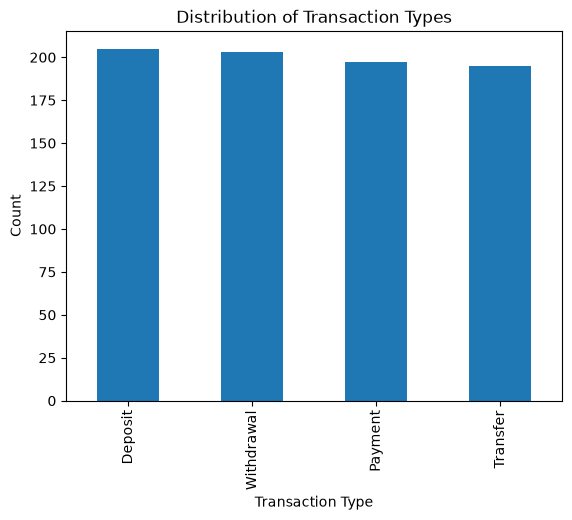

In [288]:
#Transaction Type Distribution
transaction_count = df["TransactionType"].value_counts()

transaction_count.plot(kind="bar")

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Count")

plt.show()

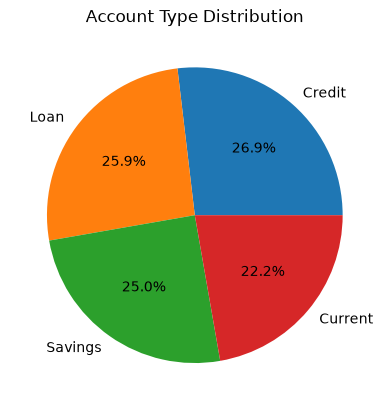

In [289]:
#Account Type Distribution
account_type = df["AccountType"].value_counts()

account_type.plot(kind="pie", autopct="%1.1f%%")

plt.title("Account Type Distribution")

plt.show()

In [290]:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"], dayfirst=True)

In [291]:
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"], format="%d-%m-%Y")

In [292]:
df["NetAmount"] = 0.0

df.loc[df["TransactionType"] == "Deposit", "NetAmount"] = df["TransactionAmount"]

df.loc[df["TransactionType"].isin(["Withdrawal", "Payment"]), "NetAmount"] = -df["TransactionAmount"]

In [293]:
net_inflow = df.groupby("AccountID")["NetAmount"].sum().reset_index(name="NetInflow")

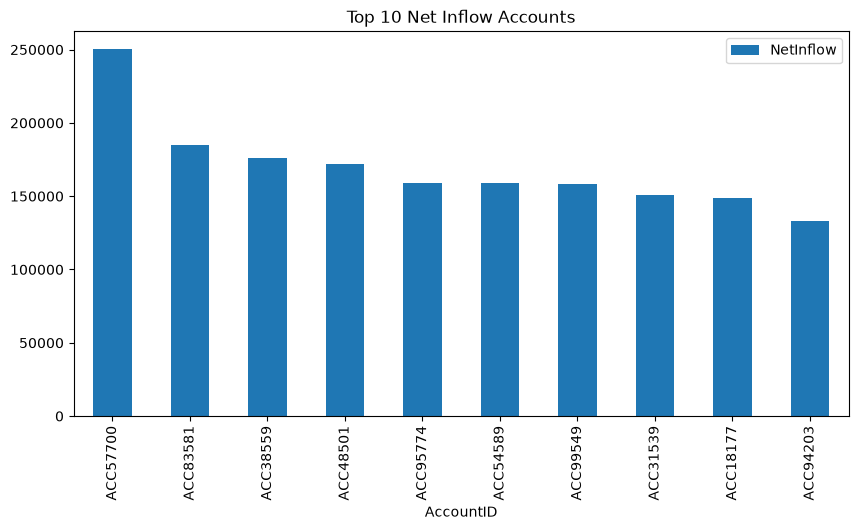

In [294]:
#Top 10 Net Inflow Accounts
top_accounts = net_inflow.sort_values(by="NetInflow", ascending=False).head(10)

top_accounts.plot(
    x="AccountID",
    y="NetInflow",
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 Net Inflow Accounts")
plt.show()

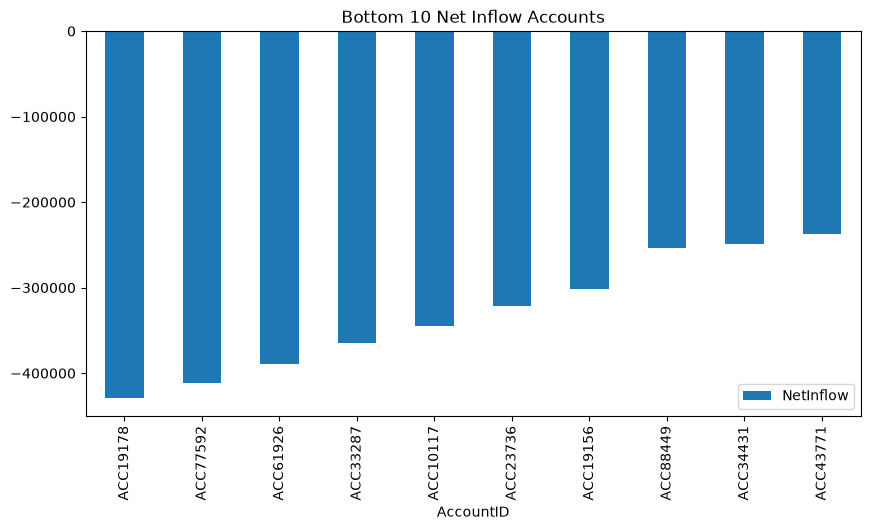

In [295]:
#Bottom 10 Net Inflow Accounts
bottom_accounts = net_inflow.sort_values(by="NetInflow").head(10)

bottom_accounts.plot(
    x="AccountID",
    y="NetInflow",
    kind="bar",
    figsize=(10,5)
)

plt.title("Bottom 10 Net Inflow Accounts")
plt.show()

In [296]:
account_activity = df.groupby("AccountID").size().reset_index(name="TransactionCount")

In [297]:
def activity_level(count):
    if count >= 6:
        return "High"
    elif count >= 3:
        return "Medium"
    else:
        return "Low"

account_activity["ActivityLevel"] = account_activity["TransactionCount"].apply(activity_level)

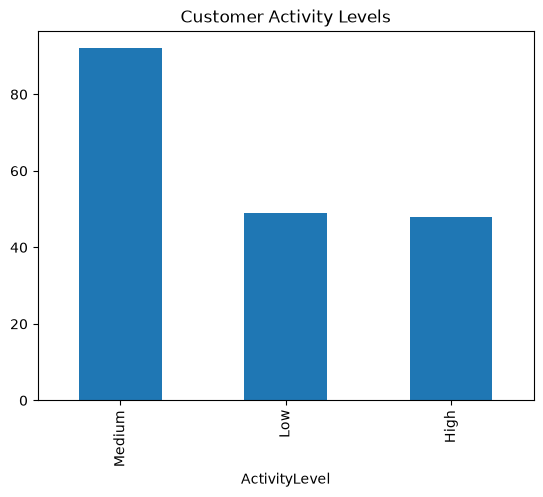

In [298]:
#Activity Levels
account_activity["ActivityLevel"].value_counts().plot(kind="bar")

plt.title("Customer Activity Levels")
plt.show()

In [299]:
#Customer Segments
df["AverageBalance"] = df.groupby("AccountID")["AccountBalance"].transform("mean")
transaction_volume = df.groupby("AccountID").size().reset_index(name="TransactionVolume")
df = df.merge(transaction_volume, on="AccountID", how="left")

In [300]:
#Customer Segments 
df["AverageBalance"] = df.groupby("AccountID")["AccountBalance"].transform("mean")
df["TransactionVolume"] = df.groupby("AccountID")["AccountID"].transform("size")

In [301]:
def customer_segment(row):
    if row["AverageBalance"] >= 81819 and row["TransactionVolume"] >= 6:
        return "Premium"
    elif row["AverageBalance"] >= 64075 and row["TransactionVolume"] >= 3:
        return "Regular"
    else:
        return "Basic"

df["CustomerSegment"] = df.apply(customer_segment, axis=1)

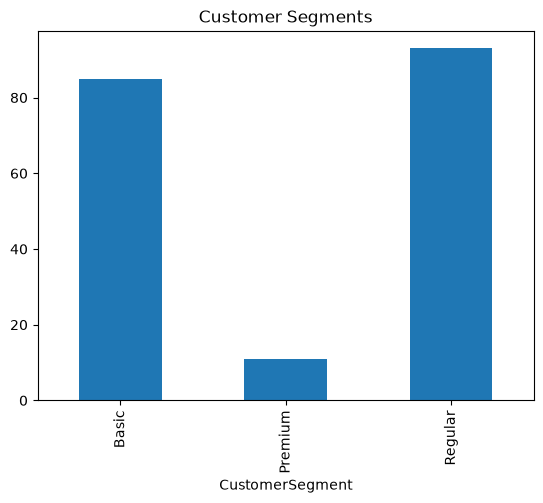

In [302]:
segment = df.groupby("CustomerSegment")["AccountID"].nunique()

segment.plot(kind="bar")

plt.title("Customer Segments")
plt.show()

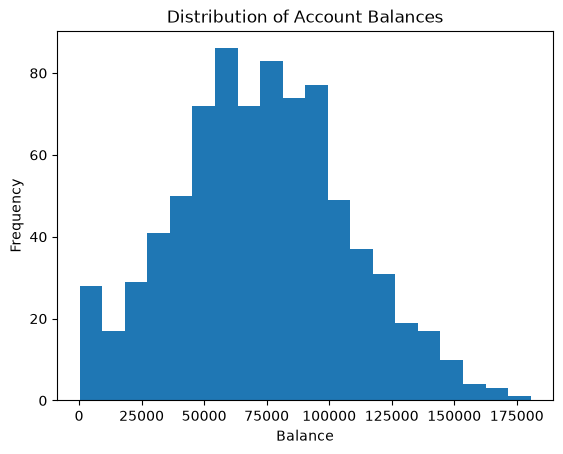

In [303]:
#Balance Distribution
plt.hist(df["AccountBalance"], bins=20)

plt.title("Distribution of Account Balances")
plt.xlabel("Balance")
plt.ylabel("Frequency")

plt.show()

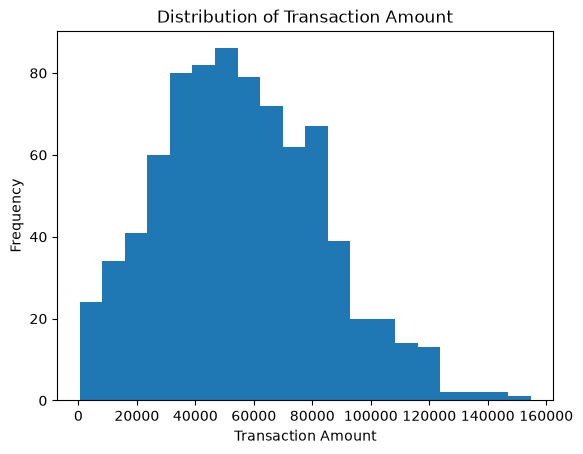

In [304]:
#Transaction Amount Distribution
plt.hist(df["TransactionAmount"], bins=20)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

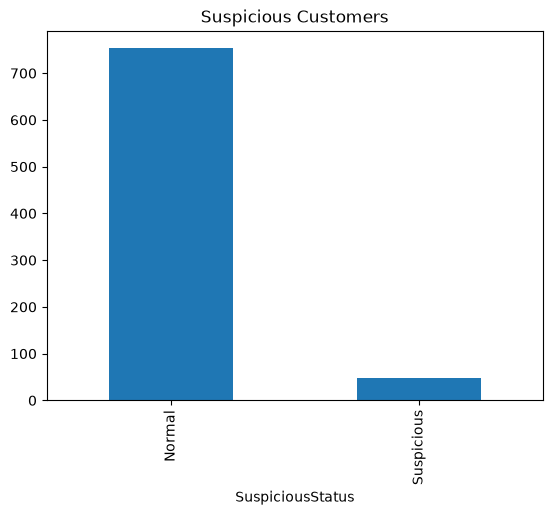

In [305]:
#Suspicious Customers
df["SuspiciousStatus"].value_counts().plot(kind="bar")

plt.title("Suspicious Customers")

plt.show()

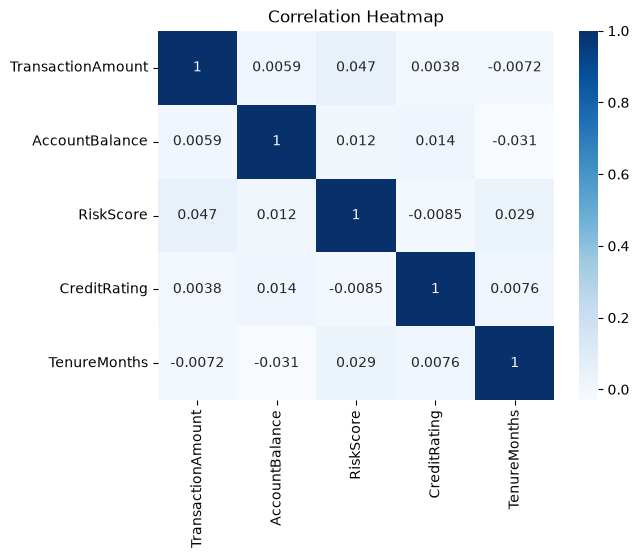

In [306]:
#Correlation Heatmap
import seaborn as sns

corr = df[[
    "TransactionAmount",
    "AccountBalance",
    "RiskScore",
    "CreditRating",
    "TenureMonths"
]].corr()

sns.heatmap(corr,
            annot=True,
            cmap="Blues")

plt.title("Correlation Heatmap")

plt.show()

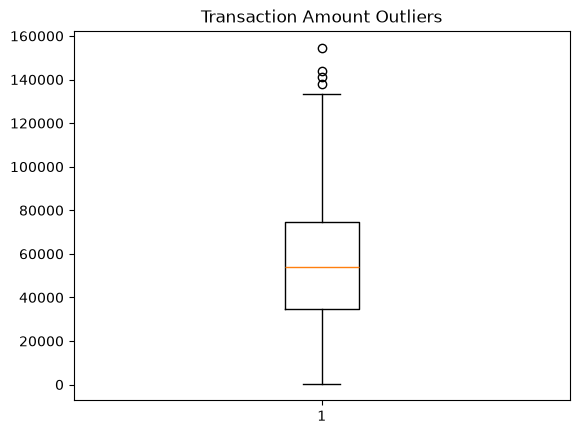

In [307]:
#Boxplot for Outliers
plt.boxplot(df["TransactionAmount"])

plt.title("Transaction Amount Outliers")

plt.show()

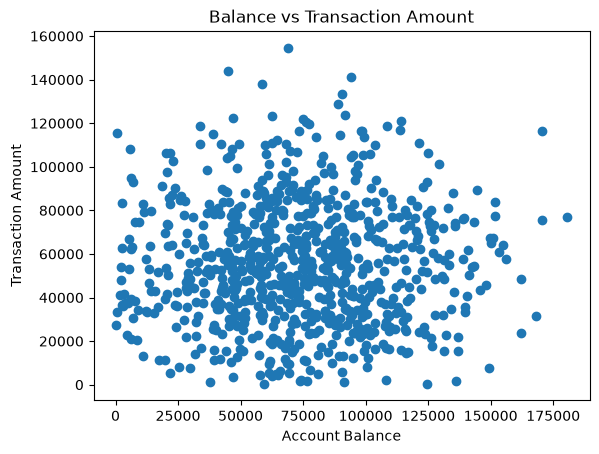

In [308]:
#Scatter Plot
plt.scatter(df["AccountBalance"],
            df["TransactionAmount"])

plt.xlabel("Account Balance")
plt.ylabel("Transaction Amount")

plt.title("Balance vs Transaction Amount")

plt.show()

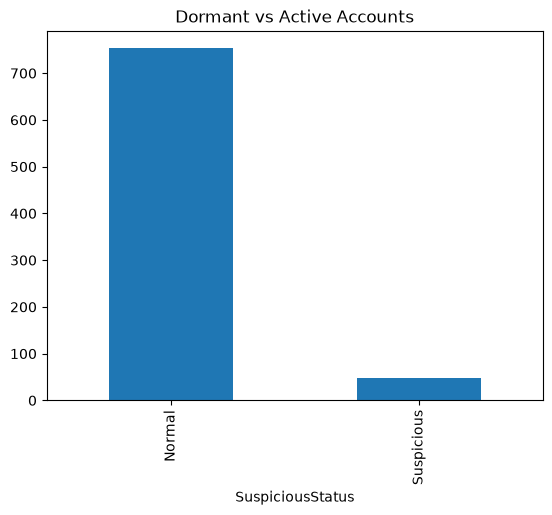

In [309]:
#Dormant vs Active Accounts
df["SuspiciousStatus"].value_counts().plot(kind="bar")

plt.title("Dormant vs Active Accounts")

plt.show()

In [310]:
# Hypothesis Testing

In [311]:
# Test whether high-volume transaction accounts have statistically higher average balances than low-volume accounts

In [312]:
#Create one record per account
account_data = df[["AccountID", "AverageBalance", "TransactionVolume"]].drop_duplicates()

print(account_data.head())

   AccountID  AverageBalance  TransactionVolume
0   ACC10117       94,082.59                  9
9   ACC10996       72,517.76                  8
17  ACC11062       73,541.33                  4
21  ACC11188       51,359.04                  2
23  ACC11285       79,923.62                  5


In [313]:
#Create High-Volume and Low-Volume Groups
high_volume = account_data[
    account_data["TransactionVolume"] >= 6
]["AverageBalance"]

low_volume = account_data[
    account_data["TransactionVolume"] <= 2
]["AverageBalance"]

In [314]:
#Perform an Independent t-test
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(high_volume, low_volume)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 0.8572519304658098
P-value: 0.3934630927731812


In [315]:
if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("High-volume accounts have significantly different average balances.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("No significant difference in average balances.")

Fail to Reject the Null Hypothesis
No significant difference in average balances.


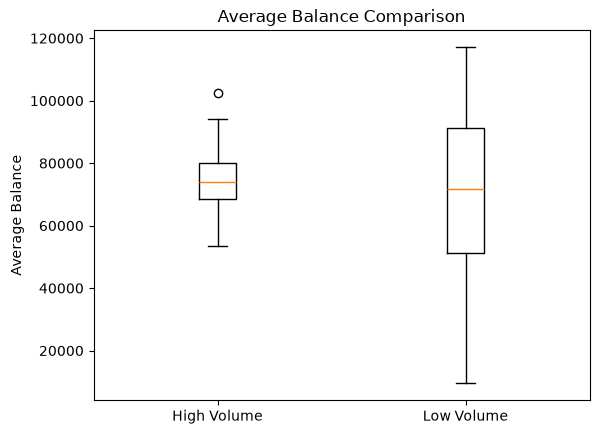

In [316]:
import matplotlib.pyplot as plt

plt.boxplot([high_volume, low_volume], tick_labels=["High Volume", "Low Volume"])

plt.title("Average Balance Comparison")
plt.ylabel("Average Balance")

plt.show()

In [317]:
# Conduct hypothesis testing based on segmentation.

In [318]:
#Create one record per account
account_segment = df[
    ["AccountID", "AverageBalance", "CustomerSegment"]
].drop_duplicates()

In [319]:
#Separate the groups
premium = account_segment[
    account_segment["CustomerSegment"] == "Premium"
]["AverageBalance"]

regular = account_segment[
    account_segment["CustomerSegment"] == "Regular"
]["AverageBalance"]

basic = account_segment[
    account_segment["CustomerSegment"] == "Basic"
]["AverageBalance"]

In [320]:
#Perform ANOVA
from scipy.stats import f_oneway

f_stat, p_value = f_oneway(premium, regular, basic)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

F-Statistic: 22.266200891693206
P-Value: 2.141066423604769e-09


In [321]:
#Interpret
if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("Average balances differ significantly across customer segments.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("No significant difference in average balances across customer segments.")

Reject the Null Hypothesis
Average balances differ significantly across customer segments.


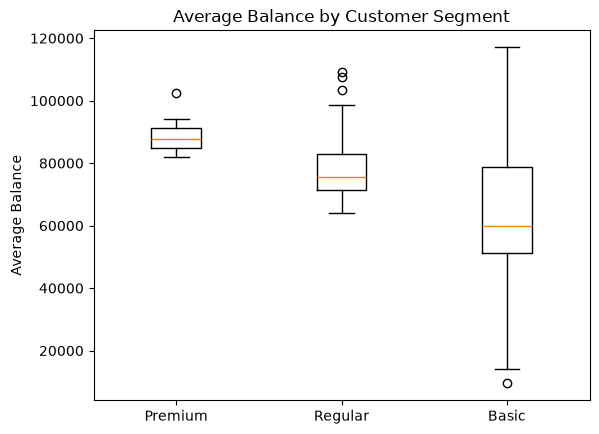

In [322]:
# Visualization
import matplotlib.pyplot as plt

plt.boxplot(
    [premium, regular, basic],
    tick_labels=["Premium", "Regular", "Basic"]
)

plt.title("Average Balance by Customer Segment")
plt.ylabel("Average Balance")

plt.show()